# Day 10: Supervised Learning with the Salary Dataset

Supervised learning trains a model on rows that already contain the correct answer. This notebook uses a salary dataset to walk through the complete workflow once with linear regression and then again as multiple linear regression trained epoch by epoch.

## Machine Learning in One Paragraph

Machine Learning lets software pick up patterns from historical data instead of following rules typed out by hand. Given employee attributes such as years of experience, education and job role together with the actual salary, a model learns how those attributes move the salary and then predicts a salary for any new employee.

### The Three Types at a Glance

- Supervised: labeled data, input X predicts output Y, for example salary, house price, spam, disease
- Unsupervised: unlabeled data, structure found without an answer column, for example customer segmentation and clustering
- Reinforcement: rewards and penalties shape behavior, for example robotics and game AI

### This Notebook Focuses on Supervised Learning

Three experiments come out of the same dataset:

- Linear Regression for salary prediction
- Multiple Linear Regression with several inputs
- Epoch based training with SGDRegressor

## Import Libraries

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Downloading the Salary Dataset

The dataset lives on Kaggle and is fetched into a local cache with the kagglehub library, so no API key is required.

Dataset: salary dataset for simple linear regression

In [2]:
import os
import kagglehub

path = kagglehub.dataset_download("abhishek14398/salary-dataset-simple-linear-regression")
print("Dataset folder:", path)

for root, dirs, files in os.walk(path):
    for file_name in files:
        if file_name.endswith(".csv"):
            csv_file = os.path.join(root, file_name)
            print("CSV found at:", csv_file)

100%|██████████| 457/457 [00:00<00:00, 674kB/s]

Extracting files...
Dataset folder: /root/.cache/kagglehub/datasets/abhishek14398/salary-dataset-simple-linear-regression/versions/1
CSV found at: /root/.cache/kagglehub/datasets/abhishek14398/salary-dataset-simple-linear-regression/versions/1/Salary_dataset.csv


In [3]:
df = pd.read_csv(csv_file)

print(df.head())
df.info()

   Unnamed: 0  YearsExperience   Salary
0           0              1.2  39344.0
1           1              1.4  46206.0
2           2              1.6  37732.0
3           3              2.1  43526.0
4           4              2.3  39892.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes


## Getting to Know the Data

### First Rows

In [4]:
df.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


### Structure

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes


### Statistical Summary

In [6]:
df.describe()

,Unnamed: 0,YearsExperience,Salary
count,30.000000,30.000000,30.000000
mean,14.500000,5.413333,76004.000000
std,8.803408,2.837888,27414.429785
min,0.000000,1.200000,37732.000000
25%,7.250000,3.300000,56721.750000
50%,14.500000,4.800000,65238.000000
75%,21.750000,7.800000,100545.750000
max,29.000000,10.600000,122392.000000


### Missing Values

In [7]:
df.isnull().sum()

,0
Unnamed: 0,0
YearsExperience,0
Salary,0


### Duplicate Rows

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.drop_duplicates(inplace=True)
df.columns

Index(['Unnamed: 0', 'YearsExperience', 'Salary'], dtype='object')

The dataset is small and clean: 30 rows with the experience in years and the salary in rupees. The Unnamed column is just a leftover index and gets ignored from here on.

### Visual Overview

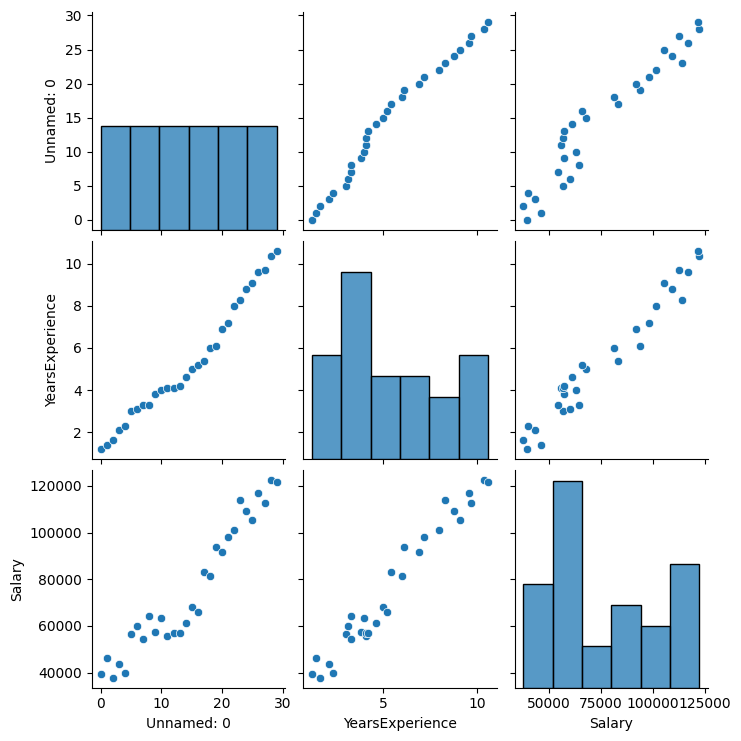

In [10]:
sns.pairplot(df)
plt.show()

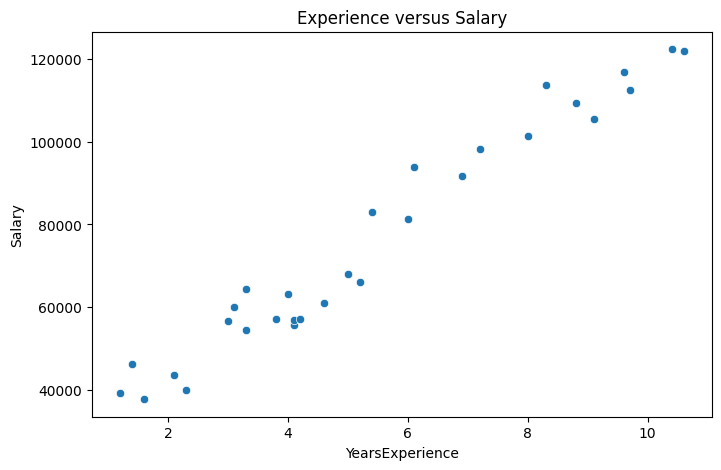

In [11]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="YearsExperience", y="Salary", data=df)
plt.title("Experience versus Salary")
plt.show()

The points rise almost along a straight line, which is exactly the situation simple linear regression handles well.

## Machine Learning Workflow

1. Define the problem statement
2. Collect the data
3. Load the data
4. Clean the data
5. Exploratory Data Analysis
6. Preprocessing
7. Feature Engineering
8. Train Test Split
9. Model Training
10. Prediction
11. Evaluation
12. Deployment

The steps after visualization follow this order.

### Feature Engineering

Original columns are not always enough. A squared experience column captures growth that speeds up with seniority, and sometimes a new column is what lifts model accuracy.

In [12]:
df["Experience_Squared"] = df["YearsExperience"] ** 2
df.head()

,Unnamed: 0,YearsExperience,Salary,Experience_Squared
0,0,1.2,39344.0,1.44
1,1,1.4,46206.0,1.96
2,2,1.6,37732.0,2.56
3,3,2.1,43526.0,4.41
4,4,2.3,39892.0,5.29


### Features and Target

- Input feature X: YearsExperience along with Experience_Squared
- Target Y: Salary

In [13]:
X = df[["YearsExperience", "Experience_Squared"]]
y = df["Salary"]

## Linear Regression on the Salary Data

### What Linear Regression Does

Linear regression is a supervised algorithm for continuous targets. It searches for the straight line that describes the input output relationship, here from years of experience to salary.

The line has the familiar form:

- y = m * x + c
- y: predicted salary
- x: years of experience
- m: slope
- c: intercept

### Train-Test Split

Usually 80 percent of the rows train the model and 20 percent remain untouched for testing.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), "train rows,", len(X_test), "test rows")

24 train rows, 6 test rows


### Feature Scaling

StandardScaler turns features into values with mean 0 and standard deviation 1.

- fit_transform on the training set: it learns the means and standard deviations from the training rows, then applies them
- transform on the test set: the test rows are scaled with the statistics learned from training, since nothing may be learned from the test set

Scaling keeps all features on a similar range, which helps the model train stably.

In [15]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Training the Model

In [16]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

### Intercept and Coefficients

- Intercept: the starting value of the line
- Coefficients: the weight each input gets in the prediction

In [17]:
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: 74208.625
Coefficients: [24437.5577623   2778.80365591]


### Predicting on the Test Set

In [18]:
y_pred = model.predict(X_test)
y_pred

array([116297.15408897,  70862.40566194, 102390.93092306,  74590.52490447,
        55305.71530665,  59832.83996149])

### Evaluation Metrics

Regression uses MAE, MSE, RMSE and R2:

- MAE: the average absolute error
- MSE: squared error, large mistakes hurt more
- RMSE: square root of MSE, in the same unit as the target
- R2: how much of the target variation the model explains, from 0 to 1

Classification problems use accuracy, precision, recall and F1 instead.

In [19]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2  :", round(r2, 4))

MAE : 6381.37
MSE : 52527916.37
RMSE: 7247.61
R2  : 0.8972


### Actual versus Predicted

In [20]:
result = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred,
})

result

,Actual Salary,Predicted Salary
0,112636.0,116297.154089
1,67939.0,70862.405662
2,113813.0,102390.930923
3,83089.0,74590.524904
4,64446.0,55305.715307
5,57190.0,59832.839961


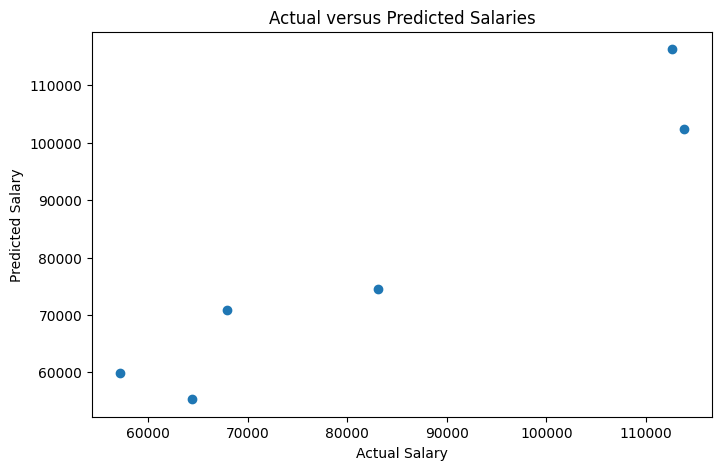

In [21]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual versus Predicted Salaries")
plt.show()

The closer the dots hug a diagonal line, the better the predictions agree with reality.

### Predicting a Brand New Salary

In [22]:
new_data = pd.DataFrame({
    "YearsExperience": [2.4],
    "Experience_Squared": [5.76],
})

new_scaled = scaler.transform(new_data)
prediction = model.predict(new_scaled)

print("Predicted Salary:", prediction[0].round(2))

Predicted Salary: 47258.47


Linear regression learned the experience to salary relationship and can now predict salaries for employees it never saw.

## A Self-Contained Dataset Copy

A small in-notebook dataset is created so the following experiments never depend on downloads.

In [23]:
data = pd.DataFrame({
    "YearsExperience": [1.1, 1.3, 1.5, 2.0, 2.2, 2.9, 3.0, 3.2, 3.2, 3.7,
                        3.9, 4.0, 4.0, 4.1, 4.5, 4.9, 5.1, 5.3, 5.9, 6.0,
                        6.8, 7.1, 7.9, 8.2, 8.7, 9.0, 9.5, 9.6, 10.3, 10.5],
    "Salary": [39343, 46205, 37731, 43525, 39891, 56642, 60150, 54445, 64445, 57189,
               63218, 55794, 56957, 57081, 61111, 67938, 66029, 83088, 81363, 93940,
               91738, 98273, 101302, 113812, 109431, 105582, 116969, 112635, 122391, 121872]
})
data.head()

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891


## Multiple Linear Regression with Epochs

Multiple linear regression uses more than one input at a time. A larger hand-made table adds Age and EducationLevel to the picture.

In [24]:
data = pd.DataFrame({
    "YearsExperience": [1.1, 1.3, 1.5, 2.0, 2.2, 2.9, 3.0, 3.2, 3.2, 3.7,
                        3.9, 4.0, 4.0, 4.1, 4.5, 4.9, 5.1, 5.3, 5.9, 6.0,
                        6.8, 7.1, 7.9, 8.2, 8.7, 9.0, 9.5, 9.6, 10.3, 10.5],
    "Age": [25, 26, 24, 28, 27, 30, 32, 31, 33, 34,
            35, 36, 36, 37, 38, 40, 41, 42, 44, 45,
            46, 47, 48, 49, 50, 51, 52, 53, 54, 55],
    "EducationLevel": [1, 2, 1, 2, 2, 3, 3, 2, 2, 3,
                       3, 3, 2, 2, 3, 3, 3, 3, 3, 3,
                       3, 3, 3, 3, 3, 3, 3, 3, 3, 3],
    "Salary": [39343, 46205, 37731, 43525, 39891, 56642, 60150, 54445, 64445, 57189,
               63218, 55794, 56957, 57081, 61111, 67938, 66029, 83088, 81363, 93940,
               91738, 98273, 101302, 113812, 109431, 105582, 116969, 112635, 122391, 121872]
})
data.head()

,YearsExperience,Age,EducationLevel,Salary
0,1.1,25,1,39343
1,1.3,26,2,46205
2,1.5,24,1,37731
3,2.0,28,2,43525
4,2.2,27,2,39891


### Features, Target and Split

In [25]:
multi_X = data[["YearsExperience", "Age", "EducationLevel"]].values
multi_y = data["Salary"].values

mX_train, mX_test, my_train, my_test = train_test_split(
    multi_X, multi_y, test_size=0.2, random_state=12
)

### Epoch Based Training

SGDRegressor updates its weights with a small step per pass instead of solving everything at once. Each pass over the data is one epoch. The table shows the training and testing error shrinking as epochs pile up; only every tenth epoch is printed to keep the log short.

In [26]:
sgd_model = SGDRegressor(max_iter=1, tol=None, eta0=0.01, random_state=12)

epochs = 100
print("Epoch  Train MSE   Test MSE")
for epoch in range(1, epochs + 1):
    sgd_model.partial_fit(mX_train, my_train)   # one pass over the data

    train_mse = mean_squared_error(my_train, sgd_model.predict(mX_train))
    test_mse = mean_squared_error(my_test, sgd_model.predict(mX_test))

    if epoch % 10 == 0 or epoch == 1:
        print(f"{epoch:5d}  {train_mse:9.2f}  {test_mse:9.2f}")

Epoch  Train MSE   Test MSE
    1  11849425446564939824103424.00  11388075747545116460449792.00
   10  4101234205309745298931712.00  3905519863936903704215552.00
   20  1755403620238494063919104.00  1683694505575214592557056.00
   30  892129453220353395392512.00  844581731562345835003904.00
   40  68789837060016594485248.00  64292187150293093318656.00
   50  161274246242665712582656.00  152375943036180944125952.00
   60  29928652587663179644928.00  30801206593095102103552.00
   70  9827829636589215023104.00  10276240794248563130368.00
   80  6575220000506421182464.00  2765868213748810383360.00
   90  10758832614930871484416.00  5126634359792667197440.00
  100  13420503152261190385664.00  6952624894927321432064.00


### Learned Parameters

In [27]:
print("Final coefficients:", sgd_model.coef_.round(3))
print("Final intercept:", round(sgd_model.intercept_[0], 3))
print("Final test R2:", round(r2_score(my_test, sgd_model.predict(mX_test)), 3))

Final coefficients: [-2.88840842e+10 -3.26072025e+09  7.27817373e+10]
Final intercept: 24090841519.199
Final test R2: -15395561872293.766


### Actual versus Predicted per Feature

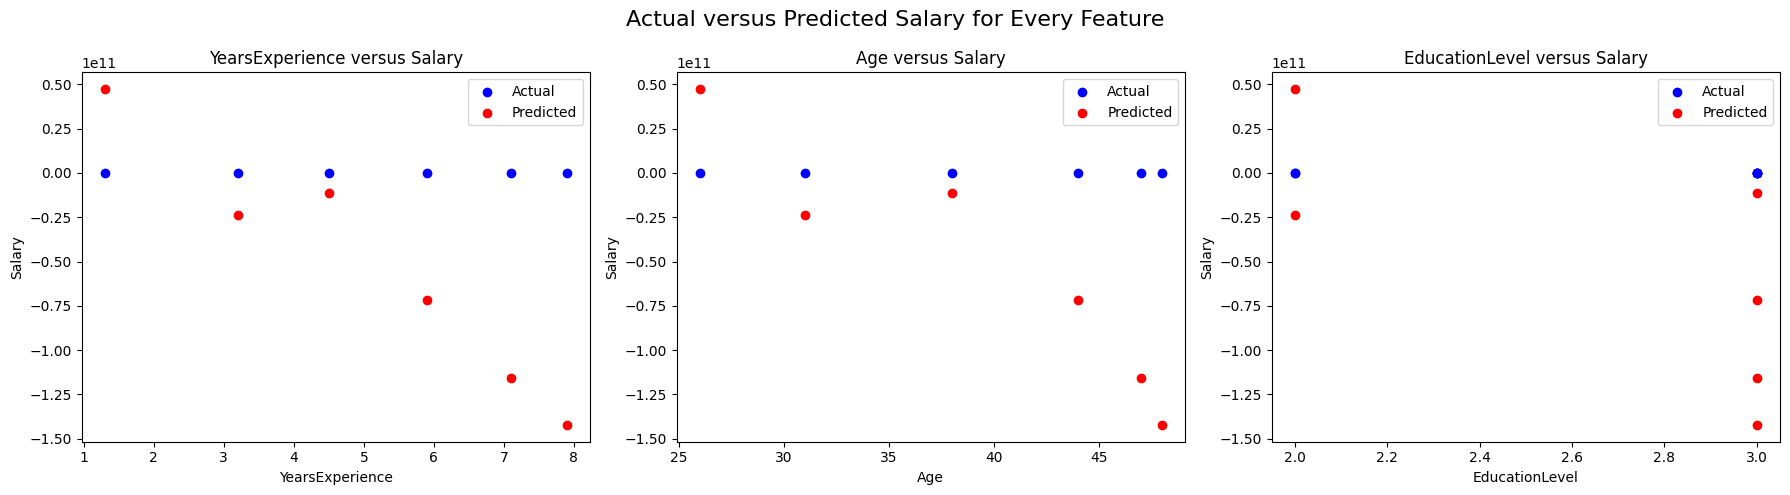

In [28]:
feature_names = ["YearsExperience", "Age", "EducationLevel"]
mX_test_df = pd.DataFrame(mX_test, columns=feature_names)
multi_pred = sgd_model.predict(mX_test)

plt.figure(figsize=(18, 5))
for idx, feat in enumerate(feature_names):
    plt.subplot(1, 3, idx + 1)
    plt.scatter(mX_test_df[feat], my_test, color="blue", label="Actual")
    plt.scatter(mX_test_df[feat], multi_pred, color="red", label="Predicted")
    plt.xlabel(feat)
    plt.ylabel("Salary")
    plt.title(f"{feat} versus Salary")
    plt.legend()

plt.suptitle("Actual versus Predicted Salary for Every Feature", fontsize=16)
plt.tight_layout()
plt.show()

## Conclusion

Linear regression managed to map experience to salary and predict for new inputs. With several inputs the same idea extends, and epoch based optimization shows the learning happening step by step. The next day applies the supervised idea to classification problems.